# 00-data-gc10 — Dữ liệu GC10-DET: giao thức, ảnh, nhãn

**Câu hỏi**: mô hình thấy những ảnh GC10 nào, ở phiên nào; dữ liệu có gì có thể làm hỏng khâu khám phá lớp mới? (Q00.02, Q03.03, Q08.02)

### Nguồn gốc (provenance)

In [1]:
# cell 0: provenance (run first)
import os, subprocess, sys
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "main.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path[:0] = [str(ROOT), str(ROOT / "lab")]
import replay; os.environ["XLA_FLAGS"] = replay._xla_flags()   # GPU deterministic mode before any jax import
git = lambda *a: subprocess.run(["git", *a], capture_output=True, text=True).stdout.strip()
print("commit", git("rev-parse", "--short", "HEAD"),
      "| code dirty", bool(git("status", "--porcelain", "--", ".", ":(exclude)runs", ":(exclude)notes",
                               ":(exclude)lab/*.ipynb", ":(exclude)lab/*.md")),
      "| XLA_FLAGS", os.environ["XLA_FLAGS"])

commit 1180a1b | code dirty False | XLA_FLAGS --xla_gpu_deterministic_ops=true


- **Kết quả**: commit `1180a1b`, code dirty False, XLA_FLAGS `--xla_gpu_deterministic_ops=true`.

## 1. Giao thức

### 1.1 Bảng ảnh của file split

In [2]:
# cell 1: the image table of the split file (lab/data_io.py)
import hashlib, json
import numpy as np, pandas as pd
import data_io
SPLIT = Path(data_io.SPLITS["gc10"])
split = json.loads(SPLIT.read_text())
df = data_io.images("gc10")
ROLES = ["S0", "reserve", "S1", "unused", "test"]
print("split", SPLIT, "| sha256", hashlib.sha256(SPLIT.read_bytes()).hexdigest()[:8], "| images", len(df))
print("roles", df["role"].value_counts().reindex(ROLES).to_dict())
df.head(3)

split splits/gc10_split.json | sha256 a8a454f8 | images 2288
roles {'S0': 764, 'reserve': 193, 'S1': 698, 'unused': 178, 'test': 455}


,path,cls,name,part,rank,row,role,cam,coil,frame
0,datasets/GC10-DET/1/img_06_425613700_00781.jpg,0,punching_hole,train,0,0,S0,06,425613700,00781
1,datasets/GC10-DET/1/img_06_3403393800_01155.jpg,0,punching_hole,train,1,1,S0,06,3403393800,01155
2,datasets/GC10-DET/1/img_03_425640000_00634.jpg,0,punching_hole,train,2,2,S0,03,425640000,00634


- **Kết quả**: 2288 ảnh: S0 764, reserve 193, S1 698, unused 178, test 455.
- **Ý nghĩa**: pool của phiên S1 = S1 (698) + 50 ảnh bốc từ reserve = 748.

### 1.2 Dựng lại file split từ dữ liệu gốc

Ghi ra file tạm, vì ghi đè file trong repo sẽ làm cũ cả 15 ảnh chụp (file split nằm trong chuỗi băm).

In [3]:
# cell 2: rebuild the split file from the raw data into a temporary file; the repo file is never written
import contextlib, importlib.util, io, tempfile
spec = importlib.util.spec_from_file_location("make_gc10_split", "scripts/make_gc10_split.py")
mk = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mk)
mk.OUT = str(Path(tempfile.mkdtemp()) / "gc10_split.json")
with contextlib.redirect_stdout(io.StringIO()) as log:
    mk.main()
same = Path(mk.OUT).read_bytes() == SPLIT.read_bytes()
print(log.getvalue().splitlines()[-3])
print("same bytes as", SPLIT, ":", same)
assert same, "the raw data do not give the split file"

images 2288 | test coils 120 of 467 | diagnostics {'multi_defect': 466, 'folder_not_in_xml': 75, 'no_xml': 6}
same bytes as splits/gc10_split.json : True


- **Kết quả**: file dựng lại trùng từng byte với file split: 2288 ảnh, 120/467 cuộn thép ở phần test, diagnostics 466/75/6.
- **Ý nghĩa**: dữ liệu gốc trên máy đúng là dữ liệu đã sinh ra file split; file trong repo không bị ghi đè.

### 1.3 Số ảnh theo lớp và vai trò, mức lệch lớp

**Cách làm**: hệ số biến thiên (coefficient of variation) CV = s / x̄, với s là độ lệch chuẩn mẫu (chia n − 1).

In [4]:
# cell 3: images per class and role, test share, class imbalance
tab = pd.crosstab(df["name"], df["role"]).reindex(index=split["classes"], columns=ROLES)
tab["test_%"] = (100 * tab["test"] / tab[ROLES].sum(axis=1)).round(1)
train = tab[["S0", "reserve", "S1", "unused"]].sum(axis=1)
cv = lambda s: s.std(ddof=1) / s.mean()                     # coefficient of variation, sample std (n - 1)
print(tab.to_string())
print(f"train max/min = {train.max()}/{train.min()} = {train.max() / train.min():.1f}x | "
      f"CV of class sizes: S0 {cv(tab.loc[tab['S0'] > 0, 'S0']):.2f}, S1 {cv(tab.loc[tab['S1'] > 0, 'S1']):.2f}")

role            S0  reserve   S1  unused  test  test_%
name                                                  
punching_hole  137       35    0       0    43    20.0
welding_line   170       43    0       0    54    20.2
crescent_gap   143       36    0       0    45    20.1
water_spot     184       46    0       0    58    20.1
oil_spot       130       33    0       0    41    20.1
silk_spot        0        0  420     106   124    19.1
inclusion        0        0  135      34    43    20.3
rolled_pit       0        0   17       5     6    21.4
crease           0        0   32       9    11    21.2
waist_folding    0        0   94      24    30    20.3
train max/min = 526/22 = 23.9x | CV of class sizes: S0 0.15, S1 1.17


- **Kết quả**: tỉ lệ test từ 19.1% (silk) tới 21.4% (rolled); train lớn nhất/nhỏ nhất = 526/22 = 23.9 lần; CV cỡ lớp: S0 0.15, S1 1.17. Trùng `01_data`.
- **Ý nghĩa**: S0 gần cân bằng; độ lệch dồn hết sang lớp mới, tức vào khâu khám phá ở S1. [SUY LUẬN] k-means có xu hướng tạo các cụm cỡ gần đều (Xiong, Wu & Chen 2009), nên dễ nuốt lớp hiếm. Test của lớp hiếm có rất ít ảnh (rolled 6, crease 11): mỗi ảnh ứng với 16.7 / 9.1 điểm recall, nên recall của hai lớp này nhảy theo từng ảnh.

### 1.4 Train và test chia theo cuộn thép (coil)

In [5]:
# cell 4: train and test are split by coil: no coil may have images on both sides
sides = df.groupby("coil")["part"].agg(lambda s: "+".join(sorted(set(s))))
print("coils", len(sides), "|", sides.value_counts().to_dict())
assert (sides != "test+train").all(), "a coil has images in train and in test"

coils 467 | {'train': 347, 'test': 120}


- **Kết quả**: 467 cuộn: 347 chỉ ở train, 120 chỉ ở test, không cuộn nào ở cả hai.
- **Ý nghĩa**: ảnh test không đến từ cuộn nào đã thấy khi train, nên các khung hình gần giống nhau của cùng một cuộn không làm điểm test cao giả.

### 1.5 Mười hai tên ảnh nằm ở hai thư mục lớp

Bộ sinh split đã bỏ 24 file này và ghi là "pixel-identical", nhưng chỉ so tên; cell này so byte và điểm ảnh (pixel).

In [6]:
# cell 5: the 12 names that sit in two class folders (removed, 24 files): same bytes? same pixels?
from PIL import Image
recs = []
for n in split["removed_duplicates"]:
    files = [Path(split["root"]) / f / n for f in split["folders"] if (Path(split["root"]) / f / n).exists()]
    sha = {hashlib.sha256(p.read_bytes()).hexdigest() for p in files}
    pix = {hashlib.sha256(np.asarray(Image.open(p)).tobytes()).hexdigest() for p in files}
    recs.append(dict(name=n, folders="+".join(p.parent.name for p in files), files=len(files), same_bytes=len(sha) == 1,
                     same_pixels=len(pix) == 1))
dup = pd.DataFrame(recs)
print(dup.to_string(index=False))
print("names", len(dup), "| files", dup["files"].sum(), "| same bytes", dup["same_bytes"].sum(),
      "| same pixels", dup["same_pixels"].sum())

                       name folders  files  same_bytes  same_pixels
 img_01_425503100_00018.jpg     3+7      2       False         True
 img_02_425392000_00984.jpg     7+8      2       False         True
 img_03_425506300_00018.jpg     1+2      2       False         True
 img_03_436068500_00002.jpg     7+8      2       False         True
 img_04_425503600_00017.jpg     2+3      2       False         True
img_06_3436814000_00687.jpg    9+10      2       False         True
 img_06_425502900_00052.jpg     1+2      2       False         True
 img_06_425505500_00052.jpg     2+8      2       False         True
 img_07_425391800_00054.jpg     1+6      2       False         True
 img_07_425502900_00052.jpg     1+2      2       False         True
 img_07_425503000_00061.jpg     4+7      2       False         True
 img_07_436163600_01161.jpg    2+10      2       False         True
names 12 | files 24 | same bytes 0 | same pixels 12


- **Kết quả**: 12 tên, 24 file, mỗi tên ở đúng 2 thư mục; 0/12 cặp trùng byte, 12/12 cặp trùng pixel. Cặp thư mục: 1+2 (3 lần), 7+8 (2 lần), 2+3, 9+10, 1+6, 2+8, 2+10, 3+7, 4+7.
- **Ý nghĩa**: câu "pixel-identical" của bộ sinh split là đúng: mỗi tên là một ảnh mang hai nhãn lớp. Hai file khác byte nhưng giải mã ra cùng điểm ảnh; [SUY LUẬN] chỗ khác nằm ở phần đầu file (metadata), không ở ảnh. Hai bản cùng tên nên cùng cuộn thép, tức cùng phía train/test; vấn đề chỉ là nhãn mâu thuẫn. Năm cặp nối lớp cũ với lớp mới (1+6, 2+8, 2+10, 3+7, 4+7); [SUY LUẬN] nếu giữ lại, cùng một ảnh có thể vừa là ảnh có nhãn ở S0 vừa nằm trong pool. Bỏ cả hai bản là hợp lý.

### 1.6 Thứ tự hàng của file đặc trưng

Hàng i của file đặc trưng là ảnh có `row` = i, nếu các run trích đặc trưng đọc đúng file split này và `build()` chưa đổi từ đó.

In [7]:
# cell 6: row i of a feature file is image i of the table: the extraction runs read this split file, build() unchanged
import importlib.util
spec = importlib.util.spec_from_file_location("exp", "scripts/exp.py")
exp = importlib.util.module_from_spec(spec)
spec.loader.exec_module(exp)
h = exp.hash_path(SPLIT)                                      # the hash exp.py writes in config.json
ext = {}
for d in sorted(Path("runs").glob("*__gc10_f[tz]_cls5first_img80pct*")):
    if "_km_" not in d.name:                                  # phase-1 runs only
        c = json.loads((d / "config.json").read_text())
        ext[d.name] = (c["inputs"].get(str(SPLIT)), c["git"]["commit"][:7])
diff = git("diff", "--stat", "97c57ee", "HEAD", "--", "feature_extractor/dino-neudet.py")
print("hash_path of the split file:", h)
for k, v in ext.items():
    print(f"  {k}: split hash {v[0]}, commit {v[1]}")
print("dino-neudet.py changed since 97c57ee:", bool(diff))
assert len(ext) == 4 and all(v == (h, "97c57ee") for v in ext.values()) and not diff

hash_path of the split file: 7203820524dbec5b
  20261005_013042__gc10_fz_cls5first_img80pct: split hash 7203820524dbec5b, commit 97c57ee
  20261005_013115__gc10_ft_cls5first_img80pct_r0: split hash 7203820524dbec5b, commit 97c57ee
  20261005_013822__gc10_ft_cls5first_img80pct_r1: split hash 7203820524dbec5b, commit 97c57ee
  20261005_014356__gc10_ft_cls5first_img80pct_r2: split hash 7203820524dbec5b, commit 97c57ee
dino-neudet.py changed since 97c57ee: False


- **Kết quả**: mã băm `exp.py` của file split là `7203820524dbec5b`; cả 4 run trích đặc trưng (fz, ft r0, r1, r2) ghi đúng mã này và chạy ở commit `97c57ee`; `dino-neudet.py` không đổi từ commit đó.
- **Ý nghĩa**: `build()` duyệt file split theo đúng thứ tự (DataLoader `shuffle=False`), nên hàng i của file đặc trưng là ảnh có `row` = i trong bảng.

### 1.7 Đầu vào bước 04 trong ảnh chụp

Đọc thẳng `snap/04.pkl` bằng pickle: file chỉ có mảng numpy, nên không cần torch, jax.

In [8]:
# cell 7: the input of step 04, read from the snapshot of the replay harness (pickle: numpy arrays only)
import pickle
run = sorted(Path("runs").glob("*__gc10_v2_ft_r0_s4"))
assert len(run) == 1, run
blob = pickle.loads((run[0] / "snap" / "04.pkl").read_bytes())
snap, meta = blob["out"], blob["meta"]
FEATURES = Path(meta["args"]["data_dir"]) / meta["args"]["pretrained_model_name"]
print("run", run[0].name, "| commit", meta["commit"][:7], "| features", FEATURES)
shapes = {k: snap[k].shape for k in ("s0_x", "pool_x", "test0_x", "test1_x")}
comp = np.bincount(np.asarray(snap["true_pool_y"]).astype(int), minlength=len(split["classes"])).tolist()
want = [data_io.NUM_KNOWN["gc10"]] * split["n_base"] + [split["n_use"][c] for c in split["classes"][split["n_base"]:]]
print(shapes, "| pool per class", comp)
assert [s[0] for s in shapes.values()] == [764, 748, 241, 214] and comp == want

run 20261020_084658__gc10_v2_ft_r0_s4 | commit 67b927d | features features/20261005_013115__gc10_ft_cls5first_img80pct_r0/dino-vitb16-sl
{'s0_x': (764, 768), 'pool_x': (748, 768), 'test0_x': (241, 768), 'test1_x': (214, 768)} | pool per class [10, 10, 10, 10, 10, 420, 135, 17, 32, 94]


- **Kết quả**: run `20261020_084658__gc10_v2_ft_r0_s4`, commit `67b927d` (= `9a07e5b`, QD21), đặc trưng `ft` r0; s0 764, pool 748, test0 241, test1 214 (× 768 chiều); pool mỗi lớp: 10 × 5 lớp cũ, silk 420, inclusion 135, rolled 17, crease 32, waist 94.
- **Ý nghĩa**: hai con số của QD23 (pool 748, test lớp mới 214) khớp với bảng ảnh ở cell 1.

### 1.8 Vai trò ảnh khớp dữ liệu pipeline dùng

**Cách làm**: so theo đa tập (multiset) các hàng đặc trưng, mỗi hàng là chuỗi byte của vector 768 chiều; loader chỉ chép hàng, không tính toán gì, nên các hàng phải trùng từng byte.

In [9]:
# cell 8: the roles of the table are the images the pipeline used: feature rows by role vs the arrays of step 04
from collections import Counter
m = FEATURES.name
X = {"train": np.load(FEATURES / f"features-{m}.npy"), "test": np.load(FEATURES / f"test_features-{m}.npy")}
def rows(part, mask):                                         # multiset of feature rows (bytes) of the masked images
    idx = df.loc[mask & (df["part"] == part), "row"].to_numpy()
    return Counter(r.tobytes() for r in X[part][idx])
arr = lambda a: Counter(r.tobytes() for r in np.asarray(a))
base = df["cls"] < split["n_base"]
pool = arr(snap["pool_x"])
extra = pool - rows("train", df["role"] == "S1")              # pool rows that are not role S1
drawn = {split["classes"][c]: sum((extra & rows("train", (df["role"] == "reserve") & (df["cls"] == c))).values())
         for c in range(split["n_base"])}
ok = {"S0 = s0_x": rows("train", df["role"] == "S0") == arr(snap["s0_x"]),
      "S1 in pool_x": not (rows("train", df["role"] == "S1") - pool),
      "rest of pool = 50 reserve, 10 per base class": sum(extra.values()) == 50 and set(drawn.values()) == {10},
      "test, base classes = test0_x": rows("test", base) == arr(snap["test0_x"]),
      "test, novel classes = test1_x": rows("test", ~base) == arr(snap["test1_x"])}
for k, v in ok.items():
    print(f"  {'OK  ' if v else 'DIFF'} {k}")
print("drawn from reserve:", drawn)
assert all(ok.values())

  OK   S0 = s0_x
  OK   S1 in pool_x
  OK   rest of pool = 50 reserve, 10 per base class
  OK   test, base classes = test0_x
  OK   test, novel classes = test1_x
drawn from reserve: {'punching_hole': 10, 'welding_line': 10, 'crescent_gap': 10, 'water_spot': 10, 'oil_spot': 10}


- **Kết quả**: cả 5 phép so OK; 50 ảnh cũ trong pool là 10 ảnh reserve của mỗi lớp cơ sở.
- **Ý nghĩa**: cột `role` đúng là các ảnh pipeline đã dùng (r0, seed 4). Giả định "loader giữ nguyên thứ tự ảnh trong mỗi lớp" đúng trên dữ liệu thật.

## 2. Ảnh

### 2.1 Kích thước ảnh

Mục 3 tính diện tích hộp lỗi theo W×H ghi trong XML, nên trước hết phải kiểm W×H đó khớp kích thước thật của file ảnh.

In [10]:
# cell 9: image size from the file header (PIL reads the header only) vs the W x H written in the XML file
import time
from PIL import Image
def header_size(p):
    with Image.open(p) as im:
        return im.size                                          # (W, H)
t = time.time()
df["W"], df["H"] = zip(*[header_size(p) for p in df["path"]])
boxes = [data_io.objects("gc10", p) for p in df["path"]]       # None: no XML file; []: no box in it
df["W_xml"] = [b[0]["W"] if b else np.nan for b in boxes]
df["H_xml"] = [b[0]["H"] if b else np.nan for b in boxes]
print(f"{time.time() - t:.1f} s | file sizes (W, H): {df.groupby(['W', 'H']).size().to_dict()}")
known = df["W_xml"].notna()
same = (df["W_xml"] == df["W"]) & (df["H_xml"] == df["H"])
print(f"XML size known: {known.sum()} / {len(df)} | equal to the file: {same.sum()} | no XML: "
      f"{sum(b is None for b in boxes)} | no box: {sum(b == [] for b in boxes)} | no size: "
      f"{sum(bool(b) and np.isnan(b[0]['W']) for b in boxes)}")

0.3 s | file sizes (W, H): {(2048, 1000): 2288}
XML size known: 2280 / 2288 | equal to the file: 2280 | no XML: 6 | no box: 2 | no size: 0


- **Kết quả**: cả 2288 ảnh đều 2048×1000 (đọc header trong 1.7 s); 2280 ảnh có W×H trong XML và cả 2280 đều khớp với file ảnh; 6 ảnh không có XML; 2 XML không có hộp nào ngoài đối tượng `d`; không XML nào thiếu kích thước.
- **Ý nghĩa**: dùng được W×H trong XML để tính diện tích hộp ở mục 3; mọi ảnh cùng cỡ nên tỉ lệ diện tích so được giữa các ảnh. Đặc trưng được trích ở 224×224 (`--resize full`): trục ngang co 2048/224 ≈ 9.1 lần, trục dọc co 1000/224 ≈ 4.5 lần, nên ảnh bị nén theo chiều ngang mạnh gấp khoảng 2 lần chiều dọc.

### 2.2 Độ sáng theo lớp và theo camera

Nếu độ sáng khác rõ theo lớp hay theo camera, đặc trưng của cả ảnh có thể tách lớp nhờ độ sáng chứ không nhờ vết lỗi.

**Cách làm**: giải mã JPEG ở 1/8 cỡ (chế độ `draft`). Khi đó mỗi điểm ảnh là trung bình của một khối 8×8, tức hệ số DC của phép biến đổi DCT (chuẩn JPEG, ITU-T T.81), nên độ sáng trung bình của cả ảnh gần như không đổi. Thử trên ảnh tổng hợp 2048×1000, độ lệch dưới 0.1 mức xám.

In [11]:
# cell 10: mean grey level of each image, decoded at 1/8 size (JPEG draft mode), by class and by camera
def mean_grey(p):
    with Image.open(p) as im:
        im.draft("L", (im.width // 8, im.height // 8))          # scaled decode: one pixel per 8 x 8 block (DC term)
        return float(np.asarray(im.convert("L"), dtype=np.float64).mean())
def grey_by(col):
    d = df.groupby(col)["grey"].describe()[["count", "25%", "50%", "75%"]].round(1)
    return d.astype({"count": int})
t = time.time()
df["grey"] = [mean_grey(p) for p in df["path"]]
print(f"{time.time() - t:.1f} s | mean grey level of the image (0-255): quartiles by class, then by camera")
print(grey_by("name").reindex(split["classes"]).to_string())
print(grey_by("cam").to_string())

9.5 s | mean grey level of the image (0-255): quartiles by class, then by camera
               count   25%    50%    75%
name                                    
punching_hole    215  82.2   92.6  101.6
welding_line     267  64.2   91.8  106.1
crescent_gap     224  44.9   59.0   76.6
water_spot       288  81.2   89.1   99.4
oil_spot         204  67.8   88.4   99.3
silk_spot        650  73.1   93.9  109.3
inclusion        212  68.3   82.7   93.9
rolled_pit        28  96.5  107.2  129.7
crease            52  72.5   93.0  112.9
waist_folding    148  73.6   99.8  112.0
     count   25%    50%    75%
cam                           
01     363  72.9   89.8  110.3
02     370  89.9  102.2  110.0
03     385  85.7   92.4   99.1
04     166  40.8   54.2   61.3
05     146  45.7   58.7   72.3
06     331  77.4   93.8  106.7
07     316  90.5   96.2  107.4
08     211  54.4   62.5   70.7


- **Kết quả**: theo camera, độ sáng chia hai nhóm rõ. Camera 04, 05, 08 tối (trung vị 54.2, 58.7, 62.5); năm camera còn lại sáng (89.8–102.2). Khoảng tứ phân vị (IQR) của camera 04 [40.8, 61.3] không chạm camera 03 [85.7, 99.1]. Theo lớp, crescent_gap tối hẳn (trung vị 59.0, IQR [44.9, 76.6]), rolled_pit sáng nhất (107.2, chỉ 28 ảnh); các lớp còn lại có trung vị 82.7–99.8. Đọc 2288 ảnh hết 10.8 s.
- **Ý nghĩa**: độ sáng khác theo camera nhiều hơn theo lớp. [SUY LUẬN] crescent_gap tối có thể vì ảnh của lớp này đến nhiều từ các camera tối, chứ không do vết lỗi; nếu đúng vậy, đặc trưng của cả ảnh có thể tách lớp này nhờ camera.

### 2.3 Lớp × camera

Kiểm lớp có gắn với camera không: nếu có, độ sáng khác nhau giữa các lớp ở 2.2 có thể chỉ là độ sáng của camera.

**Cách làm**: Cramér's V = √(χ² / (n·(min(r, c) − 1))), với χ² của bảng lớp × camera, n là số ảnh, r và c là số hàng và số cột. V = 0 khi lớp và camera độc lập; V = 1 khi biết lớp là biết camera (Cramér 1946).

In [12]:
# cell 11: class x camera table (all images) and its strength of association, Cramer's V
from scipy.stats.contingency import association
cam = pd.crosstab(df["name"], df["cam"]).reindex(split["classes"])
dark = df["cam"].isin(["04", "05", "08"])                       # the dark cameras of cell 10
cam["dark_%"] = (100 * dark.groupby(df["name"]).mean()).reindex(split["classes"]).round(0)
print(cam.to_string())
print(f"Cramer's V (class, camera) = {association(pd.crosstab(df['name'], df['cam']).to_numpy(), method='cramer'):.2f}")

cam             01   02  03  04  05   06   07  08  dark_%
name                                                     
punching_hole    0   18  94   0   0  103    0   0     0.0
welding_line    21   60  37  27  11   42   51  18    21.0
crescent_gap    57    4   2  45  50    2    5  59    69.0
water_spot      85  103  81  10   1    1    2   5     6.0
oil_spot         5   31  32  23   0   23   59  31    26.0
silk_spot      181   97  68  33  63   41  100  67    25.0
inclusion        4   36  44  22  14   39   27  26    29.0
rolled_pit       0    9  15   1   0    2    1   0     4.0
crease          10    8   5   5   5    8    9   2    23.0
waist_folding    0    4   7   0   2   70   62   3     3.0
Cramer's V (class, camera) = 0.31


- **Kết quả**: Cramér's V (lớp, camera) = 0.31. crescent_gap có 69% ảnh đến từ ba camera tối (04, 05, 08); ở các lớp khác tỉ lệ này là 0–29%. Vài lớp gần như chỉ đến từ vài camera: punching_hole 215/215 ảnh từ camera 02, 03, 06; water_spot 269/288 (93%) từ 01–03; waist_folding 132/148 (89%) từ 06–07; rolled_pit 24/28 (86%) từ 02–03. silk_spot, inclusion, crease trải đều 8 camera.
- **Ý nghĩa**: crescent_gap tối ở 2.2 khớp với việc 69% ảnh của lớp này đến từ camera tối. [SUY LUẬN] Phần lớn khác biệt độ sáng giữa các lớp có thể do camera; muốn tách hẳn phải so độ sáng trong cùng một camera. [SUY LUẬN] Lớp nào gắn chặt với camera thì đặc trưng của cả ảnh có thể mang tín hiệu camera. Ví dụ: waist_folding (89% từ camera 06–07) có cụm riêng dễ dàng ở E09.05/C3, điều đó có thể một phần nhờ camera.

### 2.4 Cuộn thép theo lớp

Ảnh của cùng một cuộn thép thường giống nhau; nếu ảnh của một lớp dồn vào ít cuộn, cụm có thể gom theo cuộn thay vì theo loại lỗi.

In [13]:
# cell 12: coils by class (all images): number of coils, images per coil, coils shared by several classes
per = df.groupby(["name", "coil"]).size()
coil = per.groupby(level="name").agg(images="sum", coils="size", median_per_coil="median", max_per_coil="max")
coil["top_coil_%"] = (100 * coil["max_per_coil"] / coil["images"]).round(0)
print(coil.reindex(split["classes"]).to_string())
shared = df.groupby("coil")["name"].nunique()
print(f"coils {len(shared)} | with 2+ classes: {(shared > 1).sum()} | images in those coils: "
      f"{df['coil'].isin(shared[shared > 1].index).sum()}")

               images  coils  median_per_coil  max_per_coil  top_coil_%
name                                                                   
punching_hole     215    150              1.0             5         2.0
welding_line      267    175              1.0             5         2.0
crescent_gap      224     82              3.0             6         3.0
water_spot        288     84              2.0            28        10.0
oil_spot          204     49              2.0            25        12.0
silk_spot         650     34              4.0           194        30.0
inclusion         212     69              2.0            16         8.0
rolled_pit         28     23              1.0             4        14.0
crease             52     32              1.0             6        12.0
waist_folding     148     29              2.0            31        21.0
coils 467 | with 2+ classes: 140 | images in those coils: 1574


- **Kết quả**: punching_hole và welding_line trải trên 150 và 175 cuộn, mỗi cuộn có tối đa 5 ảnh. silk_spot dồn nhiều nhất: 650 ảnh trong 34 cuộn, riêng một cuộn có 194 ảnh (30%). waist_folding có 148 ảnh trong 29 cuộn, cuộn lớn nhất 31 ảnh (21%); oil_spot có cuộn lớn nhất 25 ảnh (12%), water_spot 28 ảnh (10%). 140/467 cuộn có ảnh của từ 2 lớp trở lên; các cuộn này chứa 1574/2288 ảnh (69%).
- **Ý nghĩa**: [SUY LUẬN] ảnh của silk_spot và waist_folding dồn vào ít cuộn, nên phân cụm có thể tách một lớp theo cuộn; việc silk bị chia thành 3 cụm ở E09.03 có thể một phần vì vậy. Một cuộn thường chứa nhiều loại lỗi, nên gom theo cuộn không trùng với gom theo lớp.

### 2.5 Ảnh mẫu mỗi lớp

Xem bộ trích đặc trưng thực sự nhận gì: sau khi ảnh bị nén về 224×224, vết lỗi của mỗi lớp còn chiếm bao nhiêu patch.

**Cách làm**: mỗi lớp lấy ảnh S0 hoặc S1 đầu tiên có hộp của chính lớp đó (thứ tự trong file split là ngẫu nhiên, seed 0). Ảnh được co về 224×224 bằng bicubic, đúng như `dino-neudet.py` với `--resize full`; lưới 16 px là các patch của ViT-B/16. Bảng in số hộp và cỡ của hộp lớn nhất thuộc chính lớp, tính bằng patch.

         name                       image  own  other  big_w_patch  big_h_patch
punching_hole  img_06_425613700_00781.jpg    1      2          0.7          0.8
 welding_line img_02_3402617700_01009.jpg    1      2         13.5          1.0
 crescent_gap  img_01_425616200_00001.jpg    1      1          1.6          6.0
   water_spot  img_01_425007500_01234.jpg    1      0          1.9          3.5
     oil_spot  img_07_425507400_01690.jpg    2      0          0.8          1.9
    silk_spot  img_03_436152900_00582.jpg    2      0          1.8          8.3
    inclusion  img_03_424714400_00327.jpg    2      0          0.6          1.4
   rolled_pit  img_03_425501800_00019.jpg    3      0          1.5          4.1
       crease img_01_4402270500_00003.jpg    6      0         10.5          1.2
waist_folding  img_06_424826800_00494.jpg    1      0          4.5         13.2


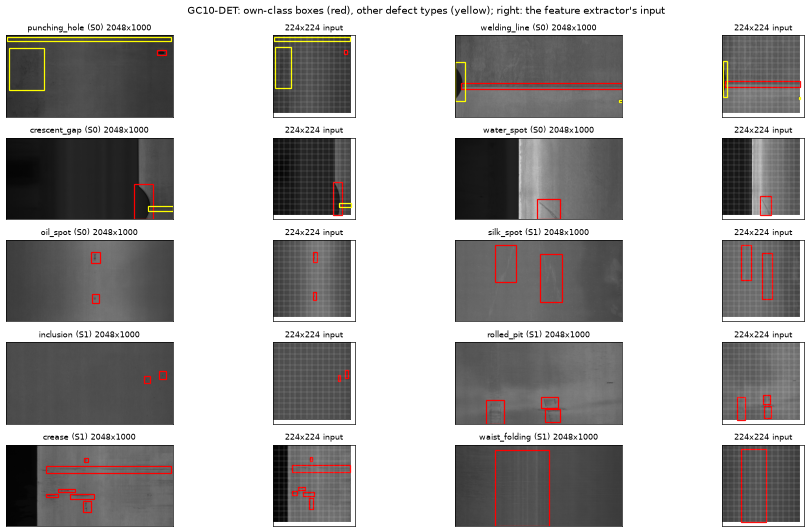

In [14]:
# cell 13: one S0/S1 image per class with a box of its own class: original with boxes (red own class, yellow others)
# and the 224 x 224 input of the feature extractor (bicubic, as dino-neudet.py --resize full) with the 16 px patch grid
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
picks, recs = [], []
for c, name in enumerate(split["classes"]):
    cand = df.index[(df["cls"] == c) & df["role"].isin(["S0", "S1"])]
    i = next(i for i in cand if boxes[i] and any(o["cls"] == c for o in boxes[i]))   # first in split order (random)
    own = [o for o in boxes[i] if o["cls"] == c]
    big = max(own, key=lambda o: (o["xmax"] - o["xmin"]) * (o["ymax"] - o["ymin"]))
    picks.append(i)
    recs.append(dict(name=name, image=Path(df.at[i, "path"]).name, own=len(own), other=len(boxes[i]) - len(own),
                     big_w_patch=round((big["xmax"] - big["xmin"]) * 224 / big["W"] / 16, 1),
                     big_h_patch=round((big["ymax"] - big["ymin"]) * 224 / big["H"] / 16, 1)))
print(pd.DataFrame(recs).to_string(index=False))
fig, axes = plt.subplots(5, 4, figsize=(16, 9), dpi=60)
for c, i in enumerate(picks):
    img = Image.open(df.at[i, "path"]).convert("RGB")
    W, H = img.size
    for k, (im, sx, sy) in enumerate(((img, 1, 1), (img.resize((224, 224), Image.BICUBIC), 224 / W, 224 / H))):
        ax = axes[c // 2, 2 * (c % 2) + k]
        ax.imshow(im)
        ax.set_xticks([])
        ax.set_yticks([])
        for o in boxes[i]:
            ax.add_patch(Rectangle((o["xmin"] * sx, o["ymin"] * sy), (o["xmax"] - o["xmin"]) * sx,
                                   (o["ymax"] - o["ymin"]) * sy, fill=False, linewidth=1.5,
                                   edgecolor="red" if o["cls"] == c else "yellow"))
        if k == 1:
            ax.vlines(range(0, 225, 16), 0, 223, colors="white", linewidth=0.3, alpha=0.5)
            ax.hlines(range(0, 225, 16), 0, 223, colors="white", linewidth=0.3, alpha=0.5)
        ax.set_title(f"{split['classes'][c]} ({df.at[i, 'role']}) {W}x{H}" if k == 0 else "224x224 input", fontsize=10)
fig.suptitle("GC10-DET: own-class boxes (red), other defect types (yellow); right: the feature extractor's input")
plt.tight_layout()
plt.show()

- **Kết quả**: cỡ hộp lớn nhất của chính lớp ở ảnh 224×224, tính bằng patch (rộng × cao):
  - dưới 1 patch bề ngang: punching_hole 0.7 × 0.8, inclusion 0.6 × 1.4, oil_spot 0.8 × 1.9;
  - cỡ vừa: water_spot 1.9 × 3.5, rolled_pit 1.5 × 4.1, crescent_gap 1.6 × 6.0, silk_spot 1.8 × 8.3;
  - vệt ngang dài nhưng chỉ cao khoảng 1 patch: welding_line 13.5 × 1.0, crease 10.5 × 1.2;
  - phủ gần hết chiều cao ảnh: waist_folding 4.5 × 13.2.

  Ảnh của punching_hole, welding_line, crescent_gap có thêm hộp của lớp khác (2, 2, 1 hộp). Trên hình, ảnh crescent_gap và water_spot có vùng tối lớn bên trái; ảnh crease có dải tối ở mép trái.
- **Ý nghĩa**: mỗi lớp chỉ có một ảnh nên đây chỉ là minh hoạ; số đại diện cho cả lớp ở mục 3. [SUY LUẬN] Lỗi nhỏ (punching_hole, inclusion, oil_spot) chiếm dưới 1% trong 196 patch, nên đặc trưng của cả ảnh mang rất ít tín hiệu của chúng. [SUY LUẬN] Vùng tối có thể là nền bên ngoài mép tấm thép. crescent_gap là lỗi ở mép tấm, nên việc lớp này tối (2.2, 2.3) có thể do vị trí chụp gần mép tấm, không chỉ do camera.

## 3. Nhãn

### 3.1 Kiểm lại mục diagnostics của file split

Tính lại ba danh sách cờ chất lượng nhãn từ XML bằng `data_io.diagnostics`, rồi so với file split. Kiểm luôn 2 XML không có hộp nào (2.1) có nằm trong `folder_not_in_xml` không.

In [15]:
# cell 14: the diagnostics of the split file computed again from the XML files (lab/data_io.py)
diag = data_io.diagnostics("gc10")
print({k: len(v) for k, v in diag.items()}, "| equal to the split file:", diag == split["diagnostics"])
nobox = [f"{Path(p).parent.name}/{Path(p).name}" for p, b in zip(df["path"], boxes) if b == []]
print("XML without box:", nobox, "| all in folder_not_in_xml:", all(f in diag["folder_not_in_xml"] for f in nobox))
assert diag == split["diagnostics"]

{'multi_defect': 466, 'folder_not_in_xml': 75, 'no_xml': 6} | equal to the split file: True
XML without box: ['7/img_06_3402617700_00988.jpg', '4/img_02_4406772100_00175.jpg'] | all in folder_not_in_xml: True


- **Kết quả**: tính lại ra 466 / 75 / 6 (multi_defect / folder_not_in_xml / no_xml), trùng mục diagnostics của file split. Hai XML không có hộp nào là `7/img_06_3402617700_00988.jpg` (inclusion) và `4/img_02_4406772100_00175.jpg` (water_spot); cả hai đều nằm trong `folder_not_in_xml`.
- **Ý nghĩa**: `objects()` đọc XML đúng theo quy tắc của bộ sinh split. Trong 75 ảnh `folder_not_in_xml`, 2 ảnh không có hộp nào; 73 ảnh còn lại có hộp, nhưng không hộp nào thuộc lớp của thư mục chứa ảnh.

### 3.2 Cờ chất lượng nhãn theo lớp và vai trò

Xem các ảnh bị gắn cờ (có nhiều loại lỗi, nhãn thư mục không có trong XML, không có XML) rơi vào lớp và vai trò nào, rồi so với `01_data` mục C1.

In [16]:
# cell 15: label-quality flags of the split file by class and role (number of flagged images)
df["key"] = [f"{Path(p).parent.name}/{Path(p).name}" for p in df["path"]]  # "folder/name", as in the split file
for k, v in diag.items():
    df[k] = df["key"].isin(v)
flag = df.groupby(["name", "role"])[list(diag)].sum()
flag.insert(0, "n", df.groupby(["name", "role"]).size())
print(flag.loc[[(c, r) for c in split["classes"] for r in ROLES if (c, r) in flag.index]].to_string())

                         n  multi_defect  folder_not_in_xml  no_xml
name          role                                                 
punching_hole S0       137            86                  0       0
              reserve   35            27                  0       0
              test      43            31                  0       0
welding_line  S0       170            85                  1       0
              reserve   43            19                  0       0
              test      54            19                  1       0
crescent_gap  S0       143            76                  0       0
              reserve   36            24                  0       0
              test      45            24                  0       0
water_spot    S0       184            13                 18       0
              reserve   46             7                  4       0
              test      58             2                  5       0
oil_spot      S0       130            10        

- **Kết quả**: bảng trùng từng ô với `01_data` mục C1 (tag `nb-v1`). Dòng `rest` cũ nay tách làm hai: reserve (lớp cũ) và unused (lớp mới).
  - multi_defect:
    - S0 có 270/764 ảnh (35%), dồn ở punching_hole 86/137, welding_line 85/170 và crescent_gap 76/143.
    - reserve có 81/193 (42%).
    - S1 chỉ có 25/698 (4%), trong đó 20 ảnh là inclusion.
    - test: lớp cũ 78/241, lớp mới 8/214.
  - folder_not_in_xml: 53/75 ảnh thuộc water_spot (27) và inclusion (26). S1 có 27 ảnh, trong đó inclusion 18. test có 15 ảnh (6 của lớp cũ, 9 của lớp mới).
  - no_xml: 6 ảnh, đều của lớp mới (waist_folding 4, silk_spot 1, crease 1).
  - rolled_pit và crease gần như sạch. Ở S1, số ảnh có nhiều loại lỗi là 0/17 và 2/32, số ảnh lệch XML là 1/17 và 3/32.
- **Ý nghĩa**:
  - Nhãn gán cho cả ảnh theo thư mục. Vì vậy punching_hole, welding_line và crescent_gap được học từ những ảnh mà 50–63% có thêm loại lỗi khác.
  - Ảnh cũ trong pool cũng vậy. Mỗi lớp cũ rút ngẫu nhiên 10 ảnh từ reserve (`_sample_known_instance` trong `utils/dataloader.py`). Lấy 10 × tỉ lệ ảnh nhiều lỗi của reserve rồi cộng cả 5 lớp, ta có kỳ vọng 21.5/50 ảnh cũ của pool có nhiều loại lỗi. Ảnh mới chỉ có 25/698.
  - Ở lớp mới, nhãn inclusion kém tin cậy nhất: ở S1 có 20 ảnh nhiều lỗi và 18 ảnh lệch XML trên 135; ở test là 8 và 7 trên 43. Vì vậy phải đọc recall của inclusion một cách thận trọng (Q08.02).
  - rolled_pit và crease gần như sạch, nên nhiễu nhãn không giải thích được vì sao hai lớp này khó khám phá.
  - [SUY LUẬN] Một phần nhầm lẫn giữa punching_hole, welding_line và crescent_gap có thể là do mỗi ảnh nhiều lỗi chỉ mang một nhãn, không hẳn do mô hình.

### 3.3 Bảng hộp lỗi

Gom các hộp lỗi trong XML thành một bảng, mỗi dòng một hộp, để dùng ở 3.4 và 3.5. Kiểm các trường hợp: toạ độ thiếu, hộp rỗng hoặc tràn ra ngoài ảnh, tên lỗi không ứng với lớp nào. Số ảnh có hộp nhưng không hộp nào thuộc lớp của chính ảnh phải bằng 73 (3.1).

In [17]:
# cell 16: all defect boxes of the XML files as one table, one row per box (img = row of df); checks of the boxes
bx = pd.DataFrame([dict(img=i, **o) for i, b in enumerate(boxes) if b for o in b])
bx["own"] = bx["cls"] == df["cls"].to_numpy()[bx["img"]]                  # box of the image's own class (folder)
bad = ((bx["xmax"] <= bx["xmin"]) | (bx["ymax"] <= bx["ymin"]) | (bx["xmin"] < 0) | (bx["ymin"] < 0)
       | (bx["xmax"] > bx["W"]) | (bx["ymax"] > bx["H"]))                  # empty, or outside the image
per = bx.groupby("img")
print(f"boxes {len(bx)} in {per.ngroups} images | own class {int(bx['own'].sum())} | other class "
      f"{int((~bx['own'] & bx['cls'].notna()).sum())} | no class {int(bx['cls'].isna().sum())} "
      f"{sorted(bx.loc[bx['cls'].isna(), 'name'].unique())}")
print(f"missing coordinates {int(bx[['xmin', 'ymin', 'xmax', 'ymax']].isna().any(axis=1).sum())} | empty or outside "
      f"{int(bad.sum())} | boxes per image: median {per.size().median():.0f}, max {per.size().max()}")
print("images with boxes but none of their own class:", int((~per["own"].any()).sum()))

boxes 3541 in 2280 images | own class 2874 | other class 667 | no class 0 []
missing coordinates 0 | empty or outside 0 | boxes per image: median 1, max 11
images with boxes but none of their own class: 73


- **Kết quả**: có 3541 hộp trong 2280 ảnh, tức 2288 ảnh trừ 6 ảnh không có XML và 2 XML không có hộp.
  - 2874 hộp thuộc lớp của chính ảnh, 667 hộp (19%) thuộc lớp khác. Tên lỗi nào cũng ứng với một trong 10 lớp.
  - Không hộp nào thiếu toạ độ, rỗng hay tràn ra ngoài ảnh.
  - Mỗi ảnh có trung vị (median) 1 hộp, nhiều nhất 11 hộp.
  - 73 ảnh có hộp nhưng không hộp nào thuộc lớp của chính ảnh, khớp 3.1.
- **Ý nghĩa**: hộp XML không có lỗi hình học (thiếu toạ độ, rỗng, tràn ảnh), nên các mục sau đo trên toàn bộ hộp mà không cần lọc. Ở Q03.03, hộp cũng dùng được ngay để cắt ảnh theo hộp làm cận trên (oracle).

### 3.4 Loại lỗi đi chung

Với mỗi lớp, đếm số ảnh S0 và S1 có thêm hộp của từng loại lỗi khác, rồi so với `01_data` mục C2. Bản cũ chỉ in 3 loại hay gặp nhất.

In [18]:
# cell 17: defect types that co-occur in the S0 and S1 images (as 01_data C2): row = class of the image (folder),
# column = another defect type with a box in the same image, value = number of images; n = images of the row
K = len(split["classes"])
s01 = df["role"].isin(["S0", "S1"]).to_numpy()
oth = bx[s01[bx["img"]] & ~bx["own"] & bx["cls"].notna()].drop_duplicates(["img", "cls"])  # once per image and type
co = pd.crosstab(df["cls"].to_numpy()[oth["img"]], oth["cls"].to_numpy().astype(int)).reindex(
    index=range(K), columns=range(K), fill_value=0)
co.index = split["classes"]
co.columns = [c.split("_")[0] for c in split["classes"]]                   # short names: punching_hole -> punching
co.insert(0, "n", np.bincount(df.loc[s01, "cls"], minlength=K))
print(co.to_string())

                 n  punching  welding  crescent  water  oil  silk  inclusion  rolled  crease  waist
punching_hole  137         0       67         9      2    7    19          1       1       3      0
welding_line   170        71        0        14      1    5     5          1       3       0      0
crescent_gap   143         3       74         0      0    0     2          0       0       0      0
water_spot     184         0        0         0      0   18    13          0       0       0      0
oil_spot       130         0        0         0      7    0     6          4       1       0      0
silk_spot      420         0        0         0      0    5     0          0       0       0      0
inclusion      135         0        0         0     23    0    13          0       1       0      0
rolled_pit      17         0        0         0      0    0     0          1       0       0      0
crease          32         0        0         0      1    0     1          1       2       0      0


- **Kết quả**: với cả 10 lớp, 3 loại đi chung nhiều nhất khớp `01_data` mục C2.
  - Ba lớp cũ punching_hole, welding_line, crescent_gap đi chung với nhau:
    - có hộp welding_line: 74/143 ảnh crescent_gap (52%) và 67/137 ảnh punching_hole (49%);
    - ngược lại, trong ảnh welding_line: 71/170 có hộp punching_hole, 14/170 có hộp crescent_gap.
  - water_spot: 18/184 ảnh có hộp oil_spot, 13 ảnh có hộp silk_spot. oil_spot: 7/130 ảnh có hộp water_spot.
  - silk_spot (lớp mới) có trong 45/764 ảnh S0 (6%): punching_hole 19, water_spot 13, oil_spot 6, welding_line 5, crescent_gap 2.
  - Lớp mới:
    - inclusion: 23/135 ảnh có hộp water_spot (17%), 13 ảnh có hộp silk_spot;
    - silk_spot chỉ đi chung với oil_spot, ở 5/420 ảnh;
    - rolled_pit, crease, waist_folding: mỗi loại đi chung xuất hiện ở nhiều nhất 2 ảnh.
- **Ý nghĩa**:
  - [SUY LUẬN] punching_hole, welding_line, crescent_gap có thể cùng đánh dấu một sự kiện: mối hàn (weld seam) nối hai cuộn thép.
    - welding_line là mối hàn tạo ra khi đổi cuộn (Lv et al., Sensors 2020).
    - Ở dây chuyền cán nguội, trước khi cán, mép thép được cắt khuyết (notching) hình bán nguyệt tại mối hàn để mối hàn khỏi đứt (US11065658).
    - Cách dò mối hàn thông thường cần đục một lỗ cạnh mối hàn (US8149409).
    - Nhưng bài GC10-DET mô tả punching_hole là lỗ đột ngoài ý muốn do hỏng cơ khí, và crescent_gap là vết cắt hình nửa vòng tròn, nên đây mới là giả thuyết.
    - Nếu đúng, mỗi ảnh chỉ mang một nhãn nên buộc phải bỏ hai loại còn lại. Khi đó không thể đọc nhầm lẫn giữa ba lớp này như lỗi thuần của mô hình.
  - Pha cơ sở đã thấy silk_spot trong 45 ảnh S0 mang nhãn lớp cũ. Bài báo dùng CIFAR100, TinyImageNet, ImageNet100, CUB200 (§4.1); mỗi ảnh trong các bộ này chỉ có một nhãn. [SUY LUẬN] Giao thức của bài báo ngầm giả định mỗi ảnh một lớp. GC10 không thoả giả định đó, kể cả ở dữ liệu có nhãn của pha cơ sở.
  - Với Q08.02: 23/135 ảnh inclusion có hộp water_spot (lớp cũ). Vì vậy nếu bộ phân lớp gán các ảnh này cho water_spot, xét theo nội dung ảnh thì chưa chắc đã sai.

### 3.5 Cỡ vùng lỗi tính bằng patch

Đo vùng lỗi của mỗi lớp chiếm bao nhiêu patch trong ảnh 224×224 mà bộ trích đặc trưng nhận, rồi so với `01_data` mục C2 (bản cũ tính bằng % diện tích ảnh).

**Cách làm**:
- Như C2, chỉ dùng hộp của chính lớp trong ảnh S0 và S1.
- Resize giữ nguyên tỉ lệ diện tích, nên số patch = (diện tích hộp / diện tích ảnh) × 196; 196 = 14 × 14 patch 16 px của ViT-B/16.
- Các cột của bảng:
  - q1, median, q3: tứ phân vị (quartile) của diện tích mỗi hộp;
  - per_image: median của tổng diện tích các hộp trong một ảnh (hộp chồng nhau bị tính hai lần);
  - w, h: median bề rộng và bề cao.
- Mọi cỡ đều tính bằng patch.

In [19]:
# cell 18: size of the own-class boxes of the S0 and S1 images in ViT-B/16 patches of the 224 x 224 input
# (01_data C2 gave % of the image); the resize keeps area fractions, so one patch = 1/196 of the image
own = bx[s01[bx["img"]] & bx["own"]].copy()
own["w"] = (own["xmax"] - own["xmin"]) / own["W"] * 14                    # width in patches (14 per row)
own["h"] = (own["ymax"] - own["ymin"]) / own["H"] * 14                    # height in patches (14 per column)
own["area"] = own["w"] * own["h"]                                          # = area / image area * 196
g = own.groupby("cls")
size = pd.DataFrame({"boxes": g.size(), "images": g["img"].nunique(), "q1": g["area"].quantile(0.25),
                     "median": g["area"].median(), "q3": g["area"].quantile(0.75),
                     "per_image": own.groupby(["cls", "img"])["area"].sum(min_count=1).groupby("cls").median(),
                     "w": g["w"].median(), "h": g["h"].median()}).round(1)
size.index = [split["classes"][int(c)] for c in size.index]
print(size.to_string())                    # per_image: median over images of the summed own-box area (patches)

               boxes  images    q1  median     q3  per_image     w     h
punching_hole    137     137   0.5     0.6    0.7        0.6   0.7   0.8
welding_line     170     169   9.3    13.1   15.1       13.1  13.9   1.0
crescent_gap     144     143   6.6    11.5   16.5       11.6   1.9   5.9
water_spot       187     166   4.5    10.2   21.7       11.5   2.0   4.7
oil_spot         304     123   0.4     0.9    2.1        2.8   0.6   1.3
silk_spot        496     418   6.7    16.4   34.4       21.1   2.0   8.9
inclusion        199     117   0.3     0.5    1.2        1.0   0.5   1.0
rolled_pit        37      16   1.6     2.5    3.9        6.3   1.3   1.8
crease            47      29   2.9     6.5   10.2       10.6   3.6   1.8
waist_folding     89      88  47.8    67.1  101.6       67.8   6.0  11.4


- **Kết quả**: so với `01_data` C2, số hộp khớp ở cả 10 lớp. Median và tứ phân vị cũng khớp sau khi đổi % ra patch (× 1.96); chỗ lệch chỉ do làm tròn. Cột images khớp 3.2: bằng số ảnh S0/S1 trừ ảnh lệch XML và ảnh không có XML, ví dụ water_spot 184 − 18 = 166.
  - Median mỗi hộp:
    - dưới 1 patch: inclusion 0.5, punching_hole 0.6, oil_spot 0.9;
    - từ 1 patch trở lên: rolled_pit 2.5, crease 6.5, water_spot 10.2, crescent_gap 11.5, welding_line 13.1, silk_spot 16.4, waist_folding 67.1 (34% ảnh).
  - Tính theo ảnh (per_image), các lớp có nhiều hộp mỗi ảnh tăng rõ: oil_spot 0.9 → 2.8, rolled_pit 2.5 → 6.3, crease 6.5 → 10.6, inclusion 0.5 → 1.0, silk_spot 16.4 → 21.1.
  - Hình dạng (w × h, patch):
    - welding_line 13.9 × 1.0: vệt ngang gần hết bề rộng ảnh, chỉ cao 1 patch;
    - crescent_gap 1.9 × 5.9 và silk_spot 2.0 × 8.9: vệt dọc.
- **Ý nghĩa**:
  - Q03.03:
    - Tính theo ảnh, trong các lớp mới chỉ inclusion thật sự nhỏ: 1.0 patch, tức 0.5% ảnh đầu vào. rolled_pit (6.3) và crease (10.6) to ngang hai lớp cũ water_spot (11.5) và crescent_gap (11.6).
    - [SUY LUẬN] Cỡ lỗi giải thích được vì sao inclusion khó khám phá, nhưng không giải thích tốt rolled_pit và crease. Với hai lớp này cần tìm nguyên nhân khác, ví dụ số ảnh ít: đây là hai lớp hiếm nhất trong S1 (17 và 32 ảnh).
    - Nếu vậy, phép kiểm của Q03.03 nên tập trung vào inclusion.
  - [SUY LUẬN] punching_hole chỉ chiếm 0.6 patch mỗi ảnh, nhỏ hơn cả inclusion, nhưng 49% ảnh của lớp này có welding_line (3.4). Mô hình cơ sở có thể nhận ra punching_hole qua ngữ cảnh đi chung hơn là qua chính lỗ đột.

### 3.6 Độ cao của punching_hole và crescent_gap so với welding_line

Kiểm giả thuyết mối hàn ở 3.4. Nếu giả thuyết đúng, trong cùng một ảnh, hộp punching_hole và crescent_gap phải nằm gần độ cao của welding_line (một vệt ngang, 3.5). Khoảng cách đó phải nhỏ hơn hẳn so với khi ghép với welding_line của ảnh khác.

**Cách làm**:
- Dùng mọi ảnh có hộp welding_line, ở mọi vai trò.
- Với mỗi hộp punching_hole hay crescent_gap, đo dy: khoảng cách theo chiều dọc từ tâm hộp tới tâm welding_line gần nhất trong cùng ảnh.
- Mốc so sánh (null) là dy tới welding_line gần nhất của từng ảnh khác.
- near là tỉ lệ dy ≤ 71 px, tức một hàng patch của ảnh 224×224.

In [20]:
# cell 19: vertical distance (pixels) from the center of each punching_hole or crescent_gap box to the nearest
# welding_line center of the same image (all roles), against the welding_line centers of every other image (null)
cy = ((bx["ymin"] + bx["ymax"]) / 2).to_numpy()                            # box centers, pixels from the top
weld = {i: cy[ix] for i, ix in bx[bx["cls"] == 1].groupby("img").groups.items()}  # image -> welding_line centers
res = {}
for c in (0, 2):                                                           # punching_hole, crescent_gap
    t = bx.index[(bx["cls"] == c) & bx["img"].isin(list(weld))]
    same = np.array([np.abs(weld[bx.at[k, "img"]] - cy[k]).min() for k in t])
    null = np.array([np.abs(w - cy[k]).min() for k in t for i, w in weld.items() if i != bx.at[k, "img"]])
    res[split["classes"][c]] = {"boxes": len(t), "images": bx.loc[t, "img"].nunique(),
                                "dy_same": np.median(same), "dy_null": np.median(null),
                                "near_same": np.mean(same <= 71), "near_null": np.mean(null <= 71)}
print(pd.DataFrame.from_dict(res, orient="index").round(2).to_string())
# dy: median distance in pixels (image height 1000); near: share within 71 px = one patch row of the 224 input

               boxes  images  dy_same  dy_null  near_same  near_null
punching_hole    222     222    173.5    262.5       0.00       0.15
crescent_gap     150     150     57.5    252.5       0.59       0.15


- **Kết quả**:
  - crescent_gap: 150 hộp trong 150 ảnh có welding_line. dy median 57.5 px, null 252.5 px. 59% số hộp nằm trong 71 px (một hàng patch) quanh welding_line; ở null là 15%.
  - punching_hole: 222 hộp trong 222 ảnh có welding_line. dy median 173.5 px, null 262.5 px. Tỉ lệ hộp nằm trong 71 px là 0.00, tức nhiều nhất 1/222 hộp; ở null là 15%.
- **Ý nghĩa**:
  - Vị trí của cả hai lớp phụ thuộc vào độ cao của welding_line, không ngẫu nhiên. crescent_gap nằm ngay ở độ cao đó. punching_hole nằm cách một đoạn, nhưng vẫn gần hơn ngẫu nhiên.
  - [SUY LUẬN] Hình học này khớp với giả thuyết mối hàn ở 3.4: crescent_gap là vết cắt khuyết mép thép tại mối hàn, punching_hole là lỗ đục cạnh mối hàn để dò mối hàn.
  - Phép kiểm chỉ phủ những ảnh có welding_line trong khung hình. Trên các ảnh này, nhầm lẫn giữa ba lớp nên được đọc là nhãn mơ hồ (ambiguous labels), không phải lỗi của mô hình.

## Summary (EN)

1. **Sessions.** Session 0 learns from 764 labeled images of the 5 old classes (S0). Session 1 discovers on a pool of 748 images: the 698 images of the 5 new classes (S1) and 50 old images, 10 per old class drawn from a reserve of 193. The 455 test images (241 old, 214 new) come from 120 coils that never appear in training. The split file is rebuilt byte-identical from the raw data (§1.1–1.3, §1.7; run `20261020_084658__gc10_v2_ft_r0_s4`).
2. **Rare and small new classes (Q03.03; Q00.02 also needs `00-data-neu`).** In S1, silk_spot has 420 images and rolled_pit 17. Per image, the defect of the image's own class covers a median of 1.0 of the 196 input patches for inclusion, 6.3 for rolled_pit, 10.6 for crease and 21.1 for silk_spot (§3.5). [inference] Size can explain why inclusion is hard to discover. It does not explain rolled_pit and crease, which are rare rather than small.
3. **Camera and coil.** Brightness depends more on the camera than on the class. Cramér's V between class and camera is 0.31, and 69% of the crescent_gap images come from the three dark cameras (04, 05, 08). One coil holds 194 of the 650 silk_spot images (§2.2–2.4). [inference] Whole-image features may group images by camera or coil, not only by defect.
4. **One label per image, several defects.** 466 of the 2288 images hold more than one defect type: 35% of S0, but 4% of S1 (§3.2). welding_line appears in 74/143 crescent_gap and 67/137 punching_hole images of S0 (§3.4). Within the same image, 59% of the crescent_gap boxes lie within one patch row of the welding_line (15% for random pairs). punching_hole boxes lie at a median of 173.5 px from it (262.5 px for random pairs) (§3.6). [inference] The three classes likely mark the same coil weld, so part of their confusions comes from label ambiguity. 45 S0 images also contain silk_spot, a new class (§3.4).
5. **Inclusion (Q08.02).** inclusion is the least reliable new label. In S1, 18/135 images have no inclusion box, 20/135 hold several defect types, and 23/135 contain water_spot, an old class (§3.2, §3.4). [inference] Some inclusion images sent to old classes may match the image content.